## 1. Imports, đường dẫn và cấu hình

Dùng toàn bộ IMDb sau khi làm sạch. Thiết lập d_model=128 theo đề; BASE_MAX_LENGTH=64 là một độ dài trong experiment sequence length để dùng chung cho head/pooling comparison.

In [1]:
from pathlib import Path
from collections import Counter
import copy
import gc
import html
import re
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

try:
    import torch
    from torch import nn
    from torch.nn.utils.rnn import pack_padded_sequence
    from torch.utils.data import DataLoader, Dataset
except ImportError as error:
    raise ImportError(
        "Chưa cài PyTorch. Cài bằng: python -m pip install torch"
    ) from error

CURRENT_DIR = Path.cwd().resolve()
lab_candidates = [CURRENT_DIR, CURRENT_DIR / "lab07", CURRENT_DIR.parent / "lab07"]
for parent in CURRENT_DIR.parents:
    lab_candidates.append(parent / "lab07")
LAB_DIR = next(
    (candidate for candidate in lab_candidates if (candidate / "W7.pdf").exists()),
    None,
)
if LAB_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục lab07 có W7.pdf.")

PROJECT_DIR = LAB_DIR.parent
DATA_PATH = PROJECT_DIR / "data" / "IMDB Dataset.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy IMDb tại {DATA_PATH}")

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20
MAX_VOCAB_SIZE = 30_000
MIN_WORD_FREQUENCY = 2
D_MODEL = 128
D_FF = 256
HEAD_COUNTS = (1, 2, 4, 8)
SEQUENCE_LENGTHS = (32, 64, 128, 256)
BASE_MAX_LENGTH = 64
BATCH_SIZE = 256
MAX_EPOCHS = 3
SEQUENCE_BATCH_SIZE = 64
SEQUENCE_MAX_EPOCHS = 2
LEARNING_RATE = 5e-4
EARLY_STOPPING_PATIENCE = 2
DROPOUT = 0.1
PAD_ID = 0
UNK_ID = 1

torch.set_num_threads(min(8, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

RESULTS_PATH = LAB_DIR / "results.csv"
POSITIONAL_ENCODING_PATH = LAB_DIR / "positional_encoding.png"
ATTENTION_HEADS_PATH = LAB_DIR / "attention_heads.png"
LEARNING_CURVES_PATH = LAB_DIR / "learning_curves.png"
CONFUSION_MATRIX_PATH = LAB_DIR / "confusion_matrix.png"

RESULT_COLUMNS = [
    "experiment", "model", "pooling", "split",
    "accuracy", "precision_positive", "recall_positive",
    "f1_positive", "f1_macro", "loss",
    "training_time_seconds", "epochs_trained", "parameters",
    "d_model", "n_heads", "d_k", "sequence_length",
    "tokens_retained_percent", "attention_matrix_elements", "notes",
]
results_rows = []

def add_result(experiment, **values):
    row = {column: np.nan for column in RESULT_COLUMNS}
    row["experiment"] = experiment
    row.update(values)
    results_rows.append(row)

print(f"Thiết bị: {DEVICE}")
print(f"Dataset: {DATA_PATH}")
print(f"d_model={D_MODEL}, batch_size={BATCH_SIZE}, epochs tối đa={MAX_EPOCHS}")


Thiết bị: cpu
Dataset: C:\Users\KIEN\OneDrive\Máy tính\NLP\data\IMDB Dataset.csv
d_model=128, batch_size=256, epochs tối đa=3


## 2. Đọc và làm sạch dữ liệu

Chuẩn hóa HTML, chữ thường và khoảng trắng; giữ từ phủ định. Bỏ duplicate có nhãn mâu thuẫn và duplicate cùng nhãn trước split để giảm leakage.

In [2]:
TEXT_COLUMN = "review"
LABEL_COLUMN = "sentiment"
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?", flags=re.IGNORECASE)

def normalize_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text.lower()).strip()

def tokenize(text):
    return TOKEN_PATTERN.findall(text)

raw_df = pd.read_csv(DATA_PATH, encoding="utf-8")
missing_text_count = int(raw_df[TEXT_COLUMN].isna().sum())
missing_label_count = int(raw_df[LABEL_COLUMN].isna().sum())

data = raw_df[[TEXT_COLUMN, LABEL_COLUMN]].dropna().copy()
data[TEXT_COLUMN] = data[TEXT_COLUMN].map(normalize_review)
data[LABEL_COLUMN] = data[LABEL_COLUMN].astype(str).str.strip().str.lower()
data = data[data[TEXT_COLUMN].map(lambda text: len(tokenize(text)) > 0)].copy()

unexpected_labels = set(data[LABEL_COLUMN].unique()) - {"positive", "negative"}
if unexpected_labels:
    raise ValueError(f"Nhãn ngoài dự kiến: {unexpected_labels}")

labels_per_text = data.groupby(TEXT_COLUMN)[LABEL_COLUMN].nunique()
conflicting_texts = set(labels_per_text[labels_per_text > 1].index)
conflicting_rows_removed = int(data[TEXT_COLUMN].isin(conflicting_texts).sum())
data = data[~data[TEXT_COLUMN].isin(conflicting_texts)].copy()

duplicate_rows_removed = int(data[TEXT_COLUMN].duplicated().sum())
data = data.drop_duplicates(subset=[TEXT_COLUMN], keep="first").reset_index(drop=True)
data["label_id"] = data[LABEL_COLUMN].map({"negative": 0, "positive": 1}).astype(int)
data["token_length"] = data[TEXT_COLUMN].map(lambda text: len(tokenize(text)))

display(pd.DataFrame([{
    "Dòng ban đầu": len(raw_df),
    "Review thiếu": missing_text_count,
    "Label thiếu": missing_label_count,
    "Dòng xung đột bị bỏ": conflicting_rows_removed,
    "Review trùng bị bỏ": duplicate_rows_removed,
    "Dòng còn lại": len(data),
}]))
display(data[[TEXT_COLUMN, LABEL_COLUMN]].head(3))
del raw_df


,Dòng ban đầu,Review thiếu,Label thiếu,Dòng xung đột bị bỏ,Review trùng bị bỏ,Dòng còn lại
0,50000,0,0,0,422,49578


,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive


## 3. Experiment 1 — Độ dài sequence

Xem min/median/mean, phân vị và histogram trước khi chọn max_length. Các độ dài chính của experiment tiếp theo theo đề là 32/64/128/256.

,Nhãn,Số review,Tỷ lệ (%)
0,positive,24882,50.187583
1,negative,24696,49.812417


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Số token,49578.0,231.205958,171.090937,6.0,127.0,173.0,280.0,451.3,589.0,903.0,2473.0


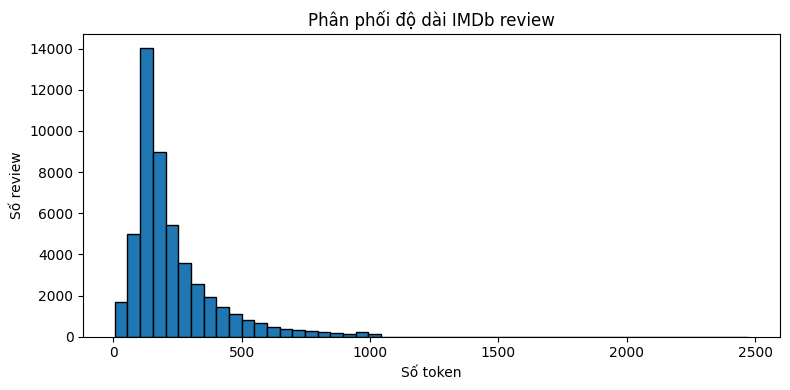

In [3]:
all_token_lengths = data["token_length"].to_numpy(dtype=np.int32, copy=True)
class_distribution = (
    data[LABEL_COLUMN]
    .value_counts()
    .rename_axis("Nhãn")
    .reset_index(name="Số review")
)
class_distribution["Tỷ lệ (%)"] = (
    class_distribution["Số review"] / class_distribution["Số review"].sum() * 100
)
display(class_distribution)
display(data["token_length"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("Số token").T)

plt.figure(figsize=(8, 4))
plt.hist(data["token_length"], bins=50, edgecolor="black")
plt.xlabel("Số token")
plt.ylabel("Số review")
plt.title("Phân phối độ dài IMDb review")
plt.tight_layout()
plt.show()


**Nhận xét — Experiment 1**

Sau khi bỏ 422 review trùng còn 49.578 review. Median độ dài là 173 token, p90 là 451; BASE_MAX_LENGTH=64 chỉ giữ 27,36% tổng token nên sẽ cắt nhiều ngữ cảnh. Dùng 64 làm mốc nhẹ cho các so sánh; Experiment 5 kiểm tra các length lớn hơn.

## 4. Chia train / validation / test

Dùng stratified 60/20/20, seed cố định. Tạo vocabulary chỉ từ train.

In [4]:
texts = data[TEXT_COLUMN].tolist()
labels = data["label_id"].to_numpy(dtype=np.int64)

x_train_val, x_test_texts, y_train_val, y_test = train_test_split(
    texts,
    labels,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=labels,
)
relative_validation_size = VALIDATION_SIZE / (1 - TEST_SIZE)
x_train_texts, x_validation_texts, y_train, y_validation = train_test_split(
    x_train_val,
    y_train_val,
    test_size=relative_validation_size,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

display(pd.DataFrame([
    {"Tập": "Train", "Số review": len(x_train_texts)},
    {"Tập": "Validation", "Số review": len(x_validation_texts)},
    {"Tập": "Test", "Số review": len(x_test_texts)},
]))
display(pd.DataFrame([
    {"Tập": "Train", "Positive (%)": 100*np.mean(y_train == 1)},
    {"Tập": "Validation", "Positive (%)": 100*np.mean(y_validation == 1)},
    {"Tập": "Test", "Positive (%)": 100*np.mean(y_test == 1)},
]))
visualization_review = x_validation_texts[0]


,Tập,Số review
0,Train,29746
1,Validation,9916
2,Test,9916


,Tập,Positive (%)
0,Train,50.184899
1,Validation,50.191610
2,Test,50.191610


## 5. Vocabulary và Token IDs

Giữ cùng vocabulary cho tất cả experiments. Mã hóa tối đa 256 tokens để dùng lại cho các max_length nhỏ hơn; lưu IDs kiểu int16 để tiết kiệm RAM.

In [5]:
word_counts = Counter()
for review in x_train_texts:
    word_counts.update(tokenize(review))

vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
for word, count in word_counts.most_common():
    if count < MIN_WORD_FREQUENCY or len(vocab) >= MAX_VOCAB_SIZE:
        break
    vocab[word] = len(vocab)
id_to_word = {index: word for word, index in vocab.items()}
VOCAB_SIZE = len(vocab)
MAX_STORED_LENGTH = max(SEQUENCE_LENGTHS)

def encode_reviews(review_list, vocabulary, max_length):
    encoded = np.zeros((len(review_list), max_length), dtype=np.int16)
    lengths = np.zeros(len(review_list), dtype=np.int32)
    for row_index, review in enumerate(review_list):
        ids = [vocabulary.get(token, UNK_ID)
               for token in tokenize(review)[:max_length]]
        lengths[row_index] = len(ids)
        if ids:
            encoded[row_index, :len(ids)] = ids
    return encoded, lengths

x_train_ids, train_lengths = encode_reviews(
    x_train_texts, vocab, MAX_STORED_LENGTH
)
x_validation_ids, validation_lengths = encode_reviews(
    x_validation_texts, vocab, MAX_STORED_LENGTH
)
x_test_ids, test_lengths = encode_reviews(
    x_test_texts, vocab, MAX_STORED_LENGTH
)

print(f"Vocabulary: {VOCAB_SIZE:,}")
print("Token IDs train:", x_train_ids.shape)
print("Token IDs validation:", x_validation_ids.shape)
print("Token IDs test:", x_test_ids.shape)
display(pd.DataFrame({
    "Token": tokenize(x_train_texts[0])[:12],
    "ID": [vocab.get(token, UNK_ID) for token in tokenize(x_train_texts[0])[:12]],
}))

del data, texts, labels, x_train_val, y_train_val, x_train_texts, x_validation_texts
del word_counts
gc.collect()


Vocabulary: 30,000
Token IDs train: (29746, 256)
Token IDs validation: (9916, 256)
Token IDs test: (9916, 256)


,Token,ID
0,no,54
1,holds,1736
2,barred,12256
3,is,7
4,a,4
5,movie,16
6,that,12
7,should,141
8,in,8
9,no,54


6644

## 6. Experiment 1 — Positional encoding

Tính PE cho d_model=4, pos=0/1/2; so sánh representation của I love NLP khi PE không có và khi PE được cộng vào embedding.

,d0 sin,d1 cos,d2 sin,d3 cos
pos 0,0.000000,1.000000,0.000000,1.00000
pos 1,0.841471,0.540302,0.010000,0.99995
pos 2,0.909297,-0.416147,0.019999,0.99980


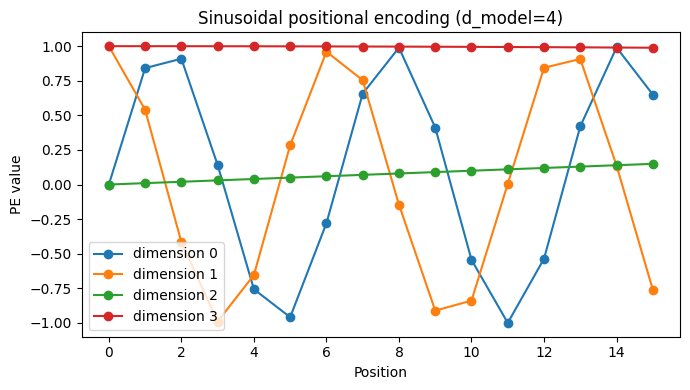

In [6]:
from positional_encoding import sinusoidal_positional_encoding
from transformer_block import TransformerBlock

pe_small = sinusoidal_positional_encoding(max_length=16, d_model=4)
display(pd.DataFrame(
    pe_small[:3],
    index=["pos 0", "pos 1", "pos 2"],
    columns=["d0 sin", "d1 cos", "d2 sin", "d3 cos"],
))

fig, axis = plt.subplots(figsize=(7, 4))
for dimension in range(4):
    axis.plot(np.arange(16), pe_small[:, dimension], marker="o",
              label=f"dimension {dimension}")
axis.set_xlabel("Position")
axis.set_ylabel("PE value")
axis.set_title("Sinusoidal positional encoding (d_model=4)")
axis.legend()
fig.tight_layout()
fig.savefig(POSITIONAL_ENCODING_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

toy_tokens = ["I", "love", "NLP"]
toy_embeddings = {
    "I": np.array([0.7, 0.1, -0.2, 0.3], dtype=np.float32),
    "love": np.array([0.2, 0.8, 0.4, -0.1], dtype=np.float32),
    "NLP": np.array([0.5, -0.3, 0.6, 0.2], dtype=np.float32),
}
toy_x = torch.tensor(
    np.stack([toy_embeddings[token] for token in toy_tokens])[None, ...],
    dtype=torch.float32,
)
toy_pe = torch.tensor(
    sinusoidal_positional_encoding(3, 4)[None, ...],
    dtype=torch.float32,
)


In [7]:
torch.manual_seed(RANDOM_STATE)
toy_block = TransformerBlock(d_model=4, n_heads=2, d_ff=8, dropout=0.0)
toy_block.eval()
with torch.no_grad():
    no_pe = toy_block(toy_x).squeeze(0)
    with_pe = toy_block(toy_x + toy_pe).squeeze(0)

positional_comparison = pd.DataFrame([
    {
        "Cách biểu diễn": "Không PE",
        "Mean representation": no_pe.mean(dim=0).numpy().tolist(),
    },
    {
        "Cách biểu diễn": "Embedding + PE",
        "Mean representation": with_pe.mean(dim=0).numpy().tolist(),
    },
])
display(positional_comparison)
print("L2 difference khi cộng PE:",
      float(torch.linalg.vector_norm(no_pe.mean(0) - with_pe.mean(0))))
print(f"Đã lưu positional encoding plot: {POSITIONAL_ENCODING_PATH}")


,Cách biểu diễn,Mean representation
0,Không PE,"[-0.7622455954551697, 0.25027933716773987, -0...."
1,Embedding + PE,"[-0.39780378341674805, 0.0656038150191307, -0...."


L2 difference khi cộng PE: 1.0455411672592163
Đã lưu positional encoding plot: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab07\positional_encoding.png


**Nhận xét — Experiment 1**

Cộng PE làm mean representation đổi với L2 distance 1,0455. Điều này cho thấy vector đầu vào đã nhận thêm thông tin vị trí; riêng ví dụ nhỏ này chưa chứng minh model hiểu ngôn ngữ.

## 7. Experiment 1 — Permutation test

Dùng cùng embedding cho dog, bites, man; so sánh dog bites man và man bites dog. Không PE thì mean-pooled self-attention phải bất biến với hoán vị; PE có thể làm pooled representation khác.

In [8]:
permutation_tokens = {
    "dog": np.array([0.8, 0.1, -0.4, 0.2], dtype=np.float32),
    "bites": np.array([0.2, 0.9, 0.1, -0.3], dtype=np.float32),
    "man": np.array([-0.2, 0.3, 0.8, 0.5], dtype=np.float32),
}
sentence_1 = ["dog", "bites", "man"]
sentence_2 = ["man", "bites", "dog"]

def encode_toy_sentence(tokens):
    values = np.stack([permutation_tokens[token] for token in tokens])
    return torch.tensor(values[None, ...], dtype=torch.float32)

x_sentence_1 = encode_toy_sentence(sentence_1)
x_sentence_2 = encode_toy_sentence(sentence_2)
toy_pe_3 = torch.tensor(
    sinusoidal_positional_encoding(3, 4)[None, ...],
    dtype=torch.float32,
)
with torch.no_grad():
    pooled_1_without_pe = toy_block(x_sentence_1).mean(dim=1)
    pooled_2_without_pe = toy_block(x_sentence_2).mean(dim=1)
    pooled_1_with_pe = toy_block(x_sentence_1 + toy_pe_3).mean(dim=1)
    pooled_2_with_pe = toy_block(x_sentence_2 + toy_pe_3).mean(dim=1)

permutation_results = {
    "difference_without_pe": float(torch.linalg.vector_norm(
        pooled_1_without_pe - pooled_2_without_pe
    )),
    "difference_with_pe": float(torch.linalg.vector_norm(
        pooled_1_with_pe - pooled_2_with_pe
    )),
}
display(pd.DataFrame([
    {"Positional information": "Không có", "Khoảng cách pooled representation":
     permutation_results["difference_without_pe"]},
    {"Positional information": "Có", "Khoảng cách pooled representation":
     permutation_results["difference_with_pe"]},
]))


,Positional information,Khoảng cách pooled representation
0,Không có,0.000000
1,Có,0.273771


**Nhận xét — Permutation experiment**

Không PE, pooled representations của dog bites man và man bites dog có distance 0. Khi thêm PE, distance là 0,2738. Kết quả toy test cho thấy positional information giúp representation phân biệt thứ tự.

## 8. Core implementation — shape tracing và Transformer block

Kiểm tra các shape trước khi train. X có shape B×T×d_model; mỗi head có d_k=d_model/n_heads.

In [9]:
sample_batch = torch.randn(8, 100, 128)
sample_padding_mask = torch.zeros(8, 100, dtype=torch.bool)
shape_block = TransformerBlock(d_model=128, n_heads=4, d_ff=256, dropout=0.0)
shape_block.eval()
with torch.no_grad():
    shape_output, shape_attention = shape_block(
        sample_batch,
        padding_mask=sample_padding_mask,
        return_attention=True,
    )

shape_table = pd.DataFrame([
    {"Tensor": "X", "Shape": tuple(sample_batch.shape)},
    {"Tensor": "Q/K/V per head", "Shape": (8, 4, 100, 32)},
    {"Tensor": "Attention scores", "Shape": tuple(shape_attention.shape)},
    {"Tensor": "Concatenated attention output", "Shape": (8, 100, 128)},
    {"Tensor": "TransformerBlock output", "Shape": tuple(shape_output.shape)},
])
display(shape_table)


,Tensor,Shape
0,X,"(8, 100, 128)"
1,Q/K/V per head,"(8, 4, 100, 32)"
2,Attention scores,"(8, 4, 100, 100)"
3,Concatenated attention output,"(8, 100, 128)"
4,TransformerBlock output,"(8, 100, 128)"


**Nhận xét — Shape tracing**

Với d_model=128 và 4 heads, d_k=32; Q/K/V có shape (8,4,100,32), scores có shape (8,4,100,100). Ghép heads đưa output về (8,100,128), và TransformerBlock giữ nguyên shape.

## 9. Chuẩn bị tokenizer, Dataset và training utilities

Dùng cùng vocabulary, split, optimizer, batch size và epochs cho các model; checkpoints chọn theo validation loss.

In [10]:
class ReviewDataset(Dataset):
    def __init__(self, encoded, lengths, labels, max_length):
        self.tokens = torch.as_tensor(encoded[:, :max_length])
        self.lengths = torch.as_tensor(
            np.minimum(lengths, max_length).astype(np.int32)
        )
        self.labels = torch.as_tensor(
            np.asarray(labels, dtype=np.float32)
        )
        if torch.any(self.lengths <= 0):
            raise ValueError("Có review rỗng sau tokenization.")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.tokens[index], self.lengths[index], self.labels[index]


def make_loaders(max_length, batch_size=BATCH_SIZE):
    train_set = ReviewDataset(x_train_ids, train_lengths, y_train, max_length)
    validation_set = ReviewDataset(
        x_validation_ids, validation_lengths, y_validation, max_length
    )
    test_set = ReviewDataset(x_test_ids, test_lengths, y_test, max_length)
    generator = torch.Generator().manual_seed(RANDOM_STATE)
    options = {
        "batch_size": batch_size,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
    }
    return (
        DataLoader(train_set, shuffle=True, generator=generator, **options),
        DataLoader(validation_set, shuffle=False, **options),
        DataLoader(test_set, shuffle=False, **options),
    )


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, pad_id):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.lstm = nn.LSTM(d_model, d_model, batch_first=True)
        self.classifier = nn.Linear(d_model, 1)

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        packed = pack_padded_sequence(
            embedded, lengths.detach().cpu().long(),
            batch_first=True, enforce_sorted=False,
        )
        _, (hidden, _) = self.lstm(packed)
        return self.classifier(hidden[-1]).squeeze(-1)


class TransformerClassifier(nn.Module):
    def __init__(
        self, vocab_size, d_model, n_heads, d_ff, pad_id,
        max_length, pooling="mean", dropout=0.1,
    ):
        super().__init__()
        if pooling not in {"mean", "cls"}:
            raise ValueError("pooling phải là mean hoặc cls")
        self.pooling = pooling
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.block = TransformerBlock(d_model, n_heads, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(d_model, 1)
        if pooling == "cls":
            self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
            nn.init.normal_(self.cls_token, mean=0.0, std=0.02)
        total_length = max_length + (1 if pooling == "cls" else 0)
        positional = sinusoidal_positional_encoding(total_length, d_model)
        self.register_buffer(
            "positional_encoding",
            torch.from_numpy(positional).unsqueeze(0),
            persistent=False,
        )

    def forward(self, token_ids, lengths=None, return_attention=False):
        valid_tokens = token_ids.ne(PAD_ID)
        x = self.embedding(token_ids)
        if self.pooling == "cls":
            cls = self.cls_token.expand(token_ids.size(0), -1, -1)
            x = torch.cat([cls, x], dim=1)
            valid_tokens = torch.cat([
                torch.ones(token_ids.size(0), 1, dtype=torch.bool,
                           device=token_ids.device),
                valid_tokens,
            ], dim=1)
        x = x + self.positional_encoding[:, :x.size(1), :].to(x.dtype)
        x, attention = self.block(
            x,
            padding_mask=~valid_tokens,
            return_attention=True,
        )
        if self.pooling == "mean":
            mask = valid_tokens.unsqueeze(-1).to(x.dtype)
            pooled = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
        else:
            pooled = x[:, 0]
        logits = self.classifier(self.dropout(pooled)).squeeze(-1)
        if return_attention:
            return logits, attention
        return logits


def metric_values(targets, predictions):
    return {
        "accuracy": accuracy_score(targets, predictions),
        "precision_positive": precision_score(
            targets, predictions, pos_label=1, zero_division=0
        ),
        "recall_positive": recall_score(
            targets, predictions, pos_label=1, zero_division=0
        ),
        "f1_positive": f1_score(
            targets, predictions, pos_label=1, zero_division=0
        ),
        "f1_macro": f1_score(
            targets, predictions, average="macro", zero_division=0
        ),
    }


def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters())


def evaluate_model(model, loader):
    criterion = nn.BCEWithLogitsLoss()
    model.eval()
    total_loss = 0.0
    targets_all, probabilities_all = [], []
    with torch.no_grad():
        for token_ids, lengths, targets in loader:
            token_ids = token_ids.to(DEVICE, dtype=torch.long, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(token_ids, lengths)
            loss = criterion(logits, targets)
            total_loss += loss.item() * len(targets)
            targets_all.extend(targets.to(torch.int64).cpu().tolist())
            probabilities_all.extend(torch.sigmoid(logits).cpu().tolist())
    targets_all = np.asarray(targets_all, dtype=np.int64)
    probabilities_all = np.asarray(probabilities_all)
    predictions_all = (probabilities_all >= 0.5).astype(np.int64)
    return (
        total_loss / len(loader.dataset),
        metric_values(targets_all, predictions_all),
        targets_all,
        predictions_all,
        probabilities_all,
    )


def train_classifier(model, model_name, max_length, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS):
    train_loader, validation_loader, _ = make_loaders(max_length, batch_size)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0
    history = []
    started = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        sum_loss = 0.0
        for token_ids, lengths, targets in train_loader:
            token_ids = token_ids.to(DEVICE, dtype=torch.long, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad()
            logits = model(token_ids, lengths)
            loss = criterion(logits, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            sum_loss += loss.item() * len(targets)

        train_loss = sum_loss / len(train_loader.dataset)
        validation_loss, validation_metrics, _, _, _ = evaluate_model(
            model, validation_loader
        )
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_f1_macro": validation_metrics["f1_macro"],
        })
        print(
            f"{model_name} | epoch {epoch}/{max_epochs} | "
            f"train loss {train_loss:.4f} | val loss {validation_loss:.4f} | "
            f"val F1 macro {validation_metrics['f1_macro']:.4f}"
        )

        if validation_loss < best_loss:
            best_loss = validation_loss
            best_epoch = epoch
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1
        if wait >= EARLY_STOPPING_PATIENCE:
            print(f"{model_name}: early stopping theo validation loss.")
            break

    if best_state is None:
        raise RuntimeError(f"{model_name} không có checkpoint hợp lệ.")
    training_seconds = time.perf_counter() - started
    model.load_state_dict(best_state)
    model.to(DEVICE)
    _, validation_metrics, _, _, _ = evaluate_model(model, validation_loader)
    return {
        "name": model_name,
        "model": model,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "epochs_trained": len(history),
        "training_seconds": training_seconds,
        "parameters": parameter_count(model),
        "validation_loss": best_loss,
        "validation_metrics": validation_metrics,
        "max_length": max_length,
    }


def add_run_row(run, experiment, split, metrics, loss=np.nan):
    row = {
        "experiment": experiment,
        "model": run["name"],
        "pooling": getattr(run["model"], "pooling", "LSTM"),
        "split": split,
        **metrics,
        "loss": loss,
        "training_time_seconds": run["training_seconds"],
        "epochs_trained": run["epochs_trained"],
        "parameters": run["parameters"],
        "d_model": D_MODEL,
        "n_heads": getattr(run["model"], "n_heads", np.nan),
        "d_k": (
            D_MODEL // getattr(run["model"], "n_heads")
            if hasattr(run["model"], "n_heads") else np.nan
        ),
        "sequence_length": run["max_length"],
        "tokens_retained_percent": np.nan,
        "attention_matrix_elements": run["max_length"] ** 2,
        "notes": f"Checkpoint theo validation loss, epoch {run['best_epoch']}.",
    }
    results_rows.append(row)
    return row


## 10. Experiment 2 — Số attention heads

Giữ d_model=128; thử 1, 2, 4, 8 heads. Cùng vocabulary, split, batch size, optimizer, learning rate và epochs. Các model khác số head được giải phóng sau khi ghi metrics để giảm RAM.

In [11]:
head_runs = {}
head_rows = []

def train_head_variant(head_count):
    torch.manual_seed(RANDOM_STATE)
    model = TransformerClassifier(
        vocab_size=VOCAB_SIZE,
        d_model=D_MODEL,
        n_heads=head_count,
        d_ff=D_FF,
        pad_id=PAD_ID,
        max_length=BASE_MAX_LENGTH,
        pooling="mean",
        dropout=DROPOUT,
    ).to(DEVICE)
    run = train_classifier(
        model,
        model_name=f"Transformer-{head_count} heads",
        max_length=BASE_MAX_LENGTH,
    )
    run["n_heads"] = head_count
    metrics = run["validation_metrics"]
    row = {
        "Heads": head_count,
        "d_k": D_MODEL // head_count,
        "Parameters": run["parameters"],
        "Epochs": run["epochs_trained"],
        "Train time (s)": run["training_seconds"],
        "Val accuracy": metrics["accuracy"],
        "Val F1 macro": metrics["f1_macro"],
    }
    head_rows.append(row)
    add_run_row(
        run, "Experiment 2 - Head count", "validation", metrics,
        loss=run["validation_loss"],
    )
    if head_count == 4:
        head_runs[head_count] = run
    else:
        head_runs[head_count] = {
            key: value for key, value in run.items() if key != "model"
        }
        del model, run
        gc.collect()
    return row


In [12]:
head_result_1 = train_head_variant(1)
display(pd.DataFrame([head_result_1]))


Transformer-1 heads | epoch 1/3 | train loss 0.6599 | val loss 0.6215 | val F1 macro 0.6331


Transformer-1 heads | epoch 2/3 | train loss 0.5696 | val loss 0.5362 | val F1 macro 0.7266


Transformer-1 heads | epoch 3/3 | train loss 0.5041 | val loss 0.5144 | val F1 macro 0.7465


,Heads,d_k,Parameters,Epochs,Train time (s),Val accuracy,Val F1 macro
0,1,128,3972609,3,110.037725,0.746975,0.74645


In [13]:
head_result_2 = train_head_variant(2)
display(pd.DataFrame([head_result_2]))


Transformer-2 heads | epoch 1/3 | train loss 0.6563 | val loss 0.6130 | val F1 macro 0.6401


Transformer-2 heads | epoch 2/3 | train loss 0.5572 | val loss 0.5289 | val F1 macro 0.7269


Transformer-2 heads | epoch 3/3 | train loss 0.4941 | val loss 0.5083 | val F1 macro 0.7477


,Heads,d_k,Parameters,Epochs,Train time (s),Val accuracy,Val F1 macro
0,2,64,3972609,3,120.015135,0.748487,0.747717


In [12]:
head_result_4 = train_head_variant(4)
display(pd.DataFrame([head_result_4]))


Transformer-4 heads | epoch 1/3 | train loss 0.6509 | val loss 0.6020 | val F1 macro 0.6517


Transformer-4 heads | epoch 2/3 | train loss 0.5447 | val loss 0.5226 | val F1 macro 0.7349


Transformer-4 heads | epoch 3/3 | train loss 0.4887 | val loss 0.5047 | val F1 macro 0.7485


,Heads,d_k,Parameters,Epochs,Train time (s),Val accuracy,Val F1 macro
0,4,32,3972609,3,137.62249,0.749697,0.748515


In [15]:
head_result_8 = train_head_variant(8)
display(pd.DataFrame([head_result_8]))


Transformer-8 heads | epoch 1/3 | train loss 0.6460 | val loss 0.5914 | val F1 macro 0.6684


Transformer-8 heads | epoch 2/3 | train loss 0.5400 | val loss 0.5184 | val F1 macro 0.7388


Transformer-8 heads | epoch 3/3 | train loss 0.4816 | val loss 0.5059 | val F1 macro 0.7474


,Heads,d_k,Parameters,Epochs,Train time (s),Val accuracy,Val F1 macro
0,8,16,3972609,3,166.750152,0.748689,0.74743


In [16]:
head_table = pd.DataFrame(head_rows).sort_values("Heads")
display(head_table)


,Heads,d_k,Parameters,Epochs,Train time (s),Val accuracy,Val F1 macro
0,1,128,3972609,3,110.037725,0.746975,0.746450
1,2,64,3972609,3,120.015135,0.748487,0.747717
2,4,32,3972609,3,134.217229,0.749697,0.748515
3,8,16,3972609,3,166.750152,0.748689,0.747430


**Nhận xét — Experiment 2**

Validation F1 macro của 1/2/4/8 heads là 0,7465/0,7477/0,7485/0,7474. d_k lần lượt 128/64/32/16, parameters đều là 3.972.609; thời gian train tăng 110,0→166,8 giây. Thêm heads không làm F1 tăng đều.

## 11. Experiment 3 — Attention head diversity

Lấy một review validation và xem attention matrix riêng cho từng head của model 4 heads. Mô tả trọng số và độ tương tự giữa heads; không gán tên ngôn ngữ nếu thiếu evidence.

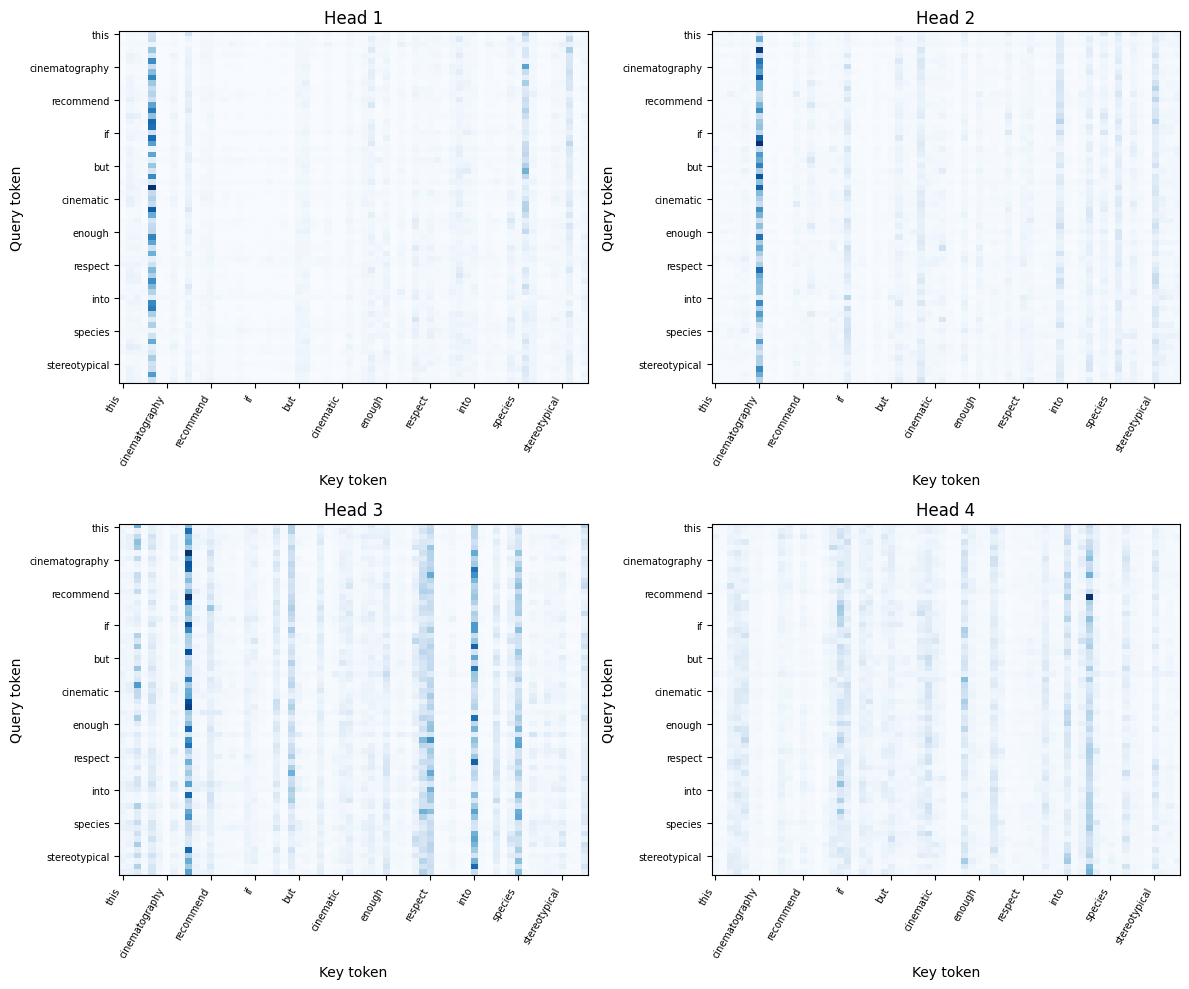

,Head 1,Head 2,Head 3,Head 4
Head 1,1.000000,0.185859,0.280367,0.287502
Head 2,0.185859,1.000000,0.147486,0.297823
Head 3,0.280367,0.147486,1.000000,0.402604
Head 4,0.287502,0.297823,0.402604,1.000000


Đã lưu attention head heatmap: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab07\attention_heads.png


In [13]:
def encode_one_review(review, max_length):
    encoded, lengths = encode_reviews([review], vocab, max_length)
    return (
        torch.as_tensor(encoded.astype(np.int64)).to(DEVICE),
        torch.as_tensor(lengths.astype(np.int64)),
        tokenize(review)[:max_length],
    )

visual_ids, visual_lengths, visual_tokens = encode_one_review(
    visualization_review, BASE_MAX_LENGTH
)
head4_model = head_runs[4]["model"]
head4_model.eval()
with torch.no_grad():
    _, head_weights = head4_model(
        visual_ids, visual_lengths, return_attention=True
    )
valid_length = int(visual_lengths[0])
head_matrices = head_weights[0, :, :valid_length, :valid_length].cpu().numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for head_index, axis in enumerate(axes.flat):
    axis.imshow(head_matrices[head_index], cmap="Blues", aspect="auto")
    axis.set_title(f"Head {head_index + 1}")
    tick_step = max(1, int(np.ceil(valid_length / 12)))
    tick_positions = list(range(0, valid_length, tick_step))
    axis.set_xticks(
        tick_positions,
        labels=[visual_tokens[index] for index in tick_positions],
        rotation=60,
        ha="right",
    )
    axis.set_yticks(
        tick_positions,
        labels=[visual_tokens[index] for index in tick_positions],
    )
    axis.tick_params(axis="both", labelsize=7)
    axis.set_xlabel("Key token")
    axis.set_ylabel("Query token")
fig.tight_layout()
fig.savefig(ATTENTION_HEADS_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

flat_heads = head_matrices.reshape(head_matrices.shape[0], -1)
norms = np.linalg.norm(flat_heads, axis=1, keepdims=True).clip(min=1e-12)
head_cosine = (flat_heads @ flat_heads.T) / (norms @ norms.T)
display(pd.DataFrame(
    head_cosine,
    index=[f"Head {i+1}" for i in range(4)],
    columns=[f"Head {i+1}" for i in range(4)],
))
print(f"Đã lưu attention head heatmap: {ATTENTION_HEADS_PATH}")


**Nhận xét — Experiment 3**

Cosine giữa attention maps của các heads nằm trong 0,147–0,403. Chúng có pattern khác nhau nhưng vẫn chia sẻ một phần; mẫu này không đủ để gán vai trò syntax/semantics cho từng head.

## 12. Experiment 4 — Transformer so với LSTM

LSTM dùng final hidden state; Transformer dùng positional encoding, Transformer block và mean pooling. Cả hai dùng cùng dữ liệu và max_length nền.

In [18]:
torch.manual_seed(RANDOM_STATE)
lstm_model = LSTMClassifier(VOCAB_SIZE, D_MODEL, PAD_ID).to(DEVICE)
lstm_run = train_classifier(
    lstm_model, model_name="LSTM", max_length=BASE_MAX_LENGTH
)
display(lstm_run["history"])


LSTM | epoch 1/3 | train loss 0.6893 | val loss 0.6676 | val F1 macro 0.5940


LSTM | epoch 2/3 | train loss 0.5997 | val loss 0.5683 | val F1 macro 0.7091


LSTM | epoch 3/3 | train loss 0.5025 | val loss 0.5154 | val F1 macro 0.7401


,epoch,train_loss,validation_loss,validation_accuracy,validation_f1_macro
0,1,0.689250,0.667639,0.594090,0.593958
1,2,0.599749,0.568282,0.709359,0.709089
2,3,0.502473,0.515416,0.740722,0.740100


,model,accuracy,precision_positive,recall_positive,f1_macro,training_time_seconds,parameters
0,LSTM,0.740722,0.770094,0.689170,0.740100,236.649756,3972225
1,Transformer-4 heads,0.749697,0.792909,0.678521,0.748515,134.217229,3972609


,model,accuracy,precision_positive,recall_positive,f1_macro,training_time_seconds,parameters
0,LSTM,0.744151,0.769197,0.700422,0.743719,236.649756,3972225
1,Transformer-4 heads,0.746874,0.785863,0.681334,0.745867,134.217229,3972609


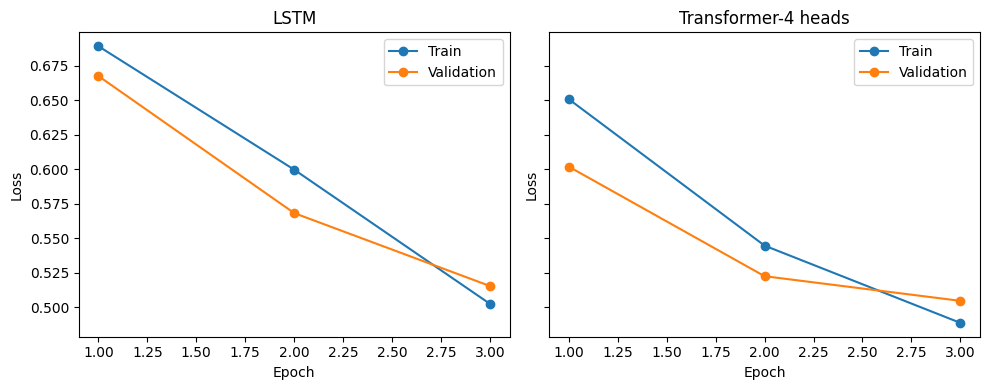

Đã lưu learning curves: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab07\learning_curves.png


In [19]:
comparison_runs = {
    "LSTM": lstm_run,
    "Transformer": head_runs[4],
}
validation_comparison_rows = []
for run in comparison_runs.values():
    row = add_run_row(
        run, "Experiment 4 - LSTM vs Transformer",
        "validation", run["validation_metrics"],
        loss=run["validation_loss"],
    )
    validation_comparison_rows.append(row)

validation_comparison = pd.DataFrame(validation_comparison_rows)
display(validation_comparison[[
    "model", "accuracy", "precision_positive", "recall_positive",
    "f1_macro", "training_time_seconds", "parameters",
]])

_, _, test_loader_base = make_loaders(BASE_MAX_LENGTH)
test_details = {}
test_comparison_rows = []
for model_name, run in comparison_runs.items():
    test_loss, test_metrics, targets, predictions, probabilities = evaluate_model(
        run["model"], test_loader_base
    )
    test_details[model_name] = {
        "targets": targets,
        "predictions": predictions,
        "probabilities": probabilities,
        "loss": test_loss,
    }
    test_row = add_run_row(
        run, "Experiment 4 - LSTM vs Transformer", "test",
        test_metrics, loss=test_loss,
    )
    test_comparison_rows.append(test_row)

test_comparison = pd.DataFrame(test_comparison_rows)
display(test_comparison[[
    "model", "accuracy", "precision_positive", "recall_positive",
    "f1_macro", "training_time_seconds", "parameters",
]])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for axis, name in zip(axes, ["LSTM", "Transformer-4 heads"]):
    run = lstm_run if name == "LSTM" else head_runs[4]
    history = run["history"]
    axis.plot(history["epoch"], history["train_loss"], marker="o", label="Train")
    axis.plot(history["epoch"], history["validation_loss"],
              marker="o", label="Validation")
    axis.set_title(name)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Loss")
    axis.legend()
fig.tight_layout()
fig.savefig(LEARNING_CURVES_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu learning curves: {LEARNING_CURVES_PATH}")


**Nhận xét — Experiment 4**

Transformer test F1 macro là 0,7459, nhỉnh hơn LSTM 0,7437; thời gian train 134,2 so với 236,6 giây và số parameters gần bằng nhau (3,973M). Chênh lệch nhỏ nên không thể nói Transformer luôn thắng. Train và validation loss đều giảm trong 3 epochs.

## 13. Experiment 5 — Sequence length

Giữ Transformer 4 heads, pooling mean và các hyperparameters cố định; thay max_length theo 32/64/128/256. Checkpoint chọn theo validation loss, metrics báo trên test.

In [20]:
sequence_rows = []

def run_sequence_length(max_length):
    torch.manual_seed(RANDOM_STATE)
    model = TransformerClassifier(
        vocab_size=VOCAB_SIZE,
        d_model=D_MODEL,
        n_heads=4,
        d_ff=D_FF,
        pad_id=PAD_ID,
        max_length=max_length,
        pooling="mean",
        dropout=DROPOUT,
    ).to(DEVICE)
    run = train_classifier(
        model,
        model_name=f"Transformer-4 heads-L{max_length}",
        max_length=max_length,
        batch_size=SEQUENCE_BATCH_SIZE,
        max_epochs=SEQUENCE_MAX_EPOCHS,
    )

    _, _, test_loader = make_loaders(max_length, batch_size=SEQUENCE_BATCH_SIZE)
    test_loss, metrics, _, _, _ = evaluate_model(run["model"], test_loader)
    retained_percent = (
        100 * np.minimum(all_token_lengths, max_length).sum()
        / all_token_lengths.sum()
    )
    elements = max_length ** 2
    row = {
        "max_length": max_length,
        "tokens_retained_percent": retained_percent,
        "attention_matrix_elements": elements,
        "test_accuracy": metrics["accuracy"],
        "test_f1_macro": metrics["f1_macro"],
        "test_loss": test_loss,
        "training_time_seconds": run["training_seconds"],
        "epochs_trained": run["epochs_trained"],
        "parameters": run["parameters"],
    }
    sequence_rows.append(row)
    add_result(
        "Experiment 5 - Sequence length",
        model="Transformer-4 heads",
        pooling="mean",
        split="test",
        accuracy=metrics["accuracy"],
        precision_positive=metrics["precision_positive"],
        recall_positive=metrics["recall_positive"],
        f1_positive=metrics["f1_positive"],
        f1_macro=metrics["f1_macro"],
        loss=test_loss,
        training_time_seconds=run["training_seconds"],
        epochs_trained=run["epochs_trained"],
        parameters=run["parameters"],
        d_model=D_MODEL,
        n_heads=4,
        d_k=D_MODEL // 4,
        sequence_length=max_length,
        tokens_retained_percent=retained_percent,
        attention_matrix_elements=elements,
        notes=f"Sequence sweep batch={SEQUENCE_BATCH_SIZE}, epochs={SEQUENCE_MAX_EPOCHS}.",
    )
    del model, run, test_loader
    gc.collect()
    return row


In [21]:
sequence_result_32 = run_sequence_length(32)
display(pd.DataFrame([sequence_result_32]))


Transformer-4 heads-L32 | epoch 1/2 | train loss 0.6296 | val loss 0.5866 | val F1 macro 0.6744


Transformer-4 heads-L32 | epoch 2/2 | train loss 0.5483 | val loss 0.5564 | val F1 macro 0.6974


,max_length,tokens_retained_percent,attention_matrix_elements,test_accuracy,test_f1_macro,test_loss,training_time_seconds,epochs_trained,parameters
0,32,13.831357,1024,0.706535,0.700284,0.552686,60.030896,2,3972609


In [22]:
sequence_result_64 = run_sequence_length(64)
display(pd.DataFrame([sequence_result_64]))


Transformer-4 heads-L64 | epoch 1/2 | train loss 0.5957 | val loss 0.5233 | val F1 macro 0.7385


Transformer-4 heads-L64 | epoch 2/2 | train loss 0.4869 | val loss 0.4780 | val F1 macro 0.7672


,max_length,tokens_retained_percent,attention_matrix_elements,test_accuracy,test_f1_macro,test_loss,training_time_seconds,epochs_trained,parameters
0,64,27.360832,4096,0.767547,0.767415,0.476194,101.770194,2,3972609


In [23]:
sequence_result_128 = run_sequence_length(128)
display(pd.DataFrame([sequence_result_128]))


Transformer-4 heads-L128 | epoch 1/2 | train loss 0.5565 | val loss 0.4583 | val F1 macro 0.7755


Transformer-4 heads-L128 | epoch 2/2 | train loss 0.4164 | val loss 0.4266 | val F1 macro 0.8012


,max_length,tokens_retained_percent,attention_matrix_elements,test_accuracy,test_f1_macro,test_loss,training_time_seconds,epochs_trained,parameters
0,128,51.543878,16384,0.802239,0.800001,0.43319,227.642961,2,3972609


In [24]:
sequence_result_256 = run_sequence_length(256)
display(pd.DataFrame([sequence_result_256]))


Transformer-4 heads-L256 | epoch 1/2 | train loss 0.5268 | val loss 0.4092 | val F1 macro 0.8110


Transformer-4 heads-L256 | epoch 2/2 | train loss 0.3642 | val loss 0.3563 | val F1 macro 0.8422


,max_length,tokens_retained_percent,attention_matrix_elements,test_accuracy,test_f1_macro,test_loss,training_time_seconds,epochs_trained,parameters
0,256,77.020716,65536,0.849133,0.849125,0.353359,601.120759,2,3972609


In [25]:
sequence_table = pd.DataFrame(sequence_rows).sort_values("max_length")
display(sequence_table)


,max_length,tokens_retained_percent,attention_matrix_elements,test_accuracy,test_f1_macro,test_loss,training_time_seconds,epochs_trained,parameters
0,32,13.831357,1024,0.706535,0.700284,0.552686,60.030896,2,3972609
1,64,27.360832,4096,0.767547,0.767415,0.476194,101.770194,2,3972609
2,128,51.543878,16384,0.802239,0.800001,0.433190,227.642961,2,3972609
3,256,77.020716,65536,0.849133,0.849125,0.353359,601.120759,2,3972609


**Nhận xét — Experiment 5**

Từ max_length 32 lên 256, tokens retained tăng 13,83%→77,02%, test F1 macro tăng 0,7003→0,8491 và train time tăng 60,0→601,1 giây. Matrix tăng 1.024→65.536 phần tử. Length dài hơn giữ thêm ngữ cảnh nhưng chi phí tăng rõ.

## 14. Pooling strategy

So sánh mean pooling với CLS-style pooling. Mean model là Transformer 4 heads đã train ở base length; chỉ train thêm CLS variant với cùng các điều kiện.

In [26]:
torch.manual_seed(RANDOM_STATE)
cls_model = TransformerClassifier(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    n_heads=4,
    d_ff=D_FF,
    pad_id=PAD_ID,
    max_length=BASE_MAX_LENGTH,
    pooling="cls",
    dropout=DROPOUT,
).to(DEVICE)
cls_run = train_classifier(
    cls_model, model_name="Transformer-4 heads-CLS",
    max_length=BASE_MAX_LENGTH,
)

pooling_runs = {
    "Mean": head_runs[4],
    "CLS": cls_run,
}
pooling_rows = []
pooling_test_details = {}
_, _, pooling_test_loader = make_loaders(BASE_MAX_LENGTH)
for pooling_name, run in pooling_runs.items():
    val_metrics = run["validation_metrics"]
    test_loss, test_metrics, targets, predictions, probabilities = evaluate_model(
        run["model"], pooling_test_loader
    )
    pooling_test_details[pooling_name] = {
        "targets": targets,
        "predictions": predictions,
        "probabilities": probabilities,
        "loss": test_loss,
    }
    pooling_rows.append({
        "Pooling": pooling_name,
        "Validation F1 macro": val_metrics["f1_macro"],
        "Test accuracy": test_metrics["accuracy"],
        "Test F1 macro": test_metrics["f1_macro"],
        "Training time (s)": run["training_seconds"],
        "Parameters": run["parameters"],
    })
    add_run_row(run, "Experiment 6 - Pooling", "validation",
                val_metrics, loss=run["validation_loss"])
    add_run_row(run, "Experiment 6 - Pooling", "test",
                test_metrics, loss=test_loss)

pooling_table = pd.DataFrame(pooling_rows)
display(pooling_table)

selected_transformer_pooling = max(
    pooling_runs,
    key=lambda name: pooling_runs[name]["validation_metrics"]["f1_macro"],
)
selected_transformer_run = pooling_runs[selected_transformer_pooling]
print("Pooling chọn theo validation F1 macro:", selected_transformer_pooling)


Transformer-4 heads-CLS | epoch 1/3 | train loss 0.6613 | val loss 0.5839 | val F1 macro 0.6845


Transformer-4 heads-CLS | epoch 2/3 | train loss 0.5548 | val loss 0.5209 | val F1 macro 0.7349


Transformer-4 heads-CLS | epoch 3/3 | train loss 0.5072 | val loss 0.5332 | val F1 macro 0.7191


,Pooling,Validation F1 macro,Test accuracy,Test F1 macro,Training time (s),Parameters
0,Mean,0.748515,0.746874,0.745867,134.217229,3972609
1,CLS,0.734885,0.734369,0.734060,138.066440,3972737


Pooling chọn theo validation F1 macro: Mean


**Nhận xét — Experiment 6**

Mean pooling đạt test F1 macro 0,7459; CLS đạt 0,7341. Mean tốt hơn một chút trong lần chạy này, với train time 134,2 so với 138,1 giây. Chênh lệch nhỏ nên chưa thể khái quát.

Model cuối chọn theo validation F1 macro: Transformer mean


,Model,accuracy,precision_positive,recall_positive,f1_positive,f1_macro,Test loss
0,Transformer mean,0.746874,0.785863,0.681334,0.729875,0.745867,0.503486


,Dự đoán: negative,Dự đoán: positive
Thật: negative,4015,924
Thật: positive,1586,3391


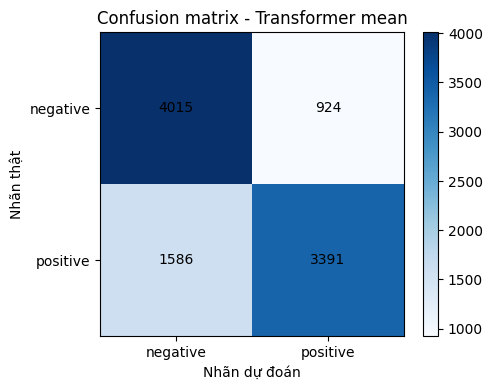

Đã lưu confusion matrix: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab07\confusion_matrix.png


In [27]:
final_candidates = {
    "LSTM": lstm_run,
    "Transformer mean": head_runs[4],
    "Transformer CLS": cls_run,
}
selected_final_name = max(
    final_candidates,
    key=lambda name: final_candidates[name]["validation_metrics"]["f1_macro"],
)
if selected_final_name == "LSTM":
    selected_test_details = test_details["LSTM"]
elif selected_final_name == "Transformer mean":
    selected_test_details = test_details["Transformer"]
else:
    selected_test_details = pooling_test_details["CLS"]

final_targets = selected_test_details["targets"]
final_predictions = selected_test_details["predictions"]
final_metrics = metric_values(final_targets, final_predictions)
print("Model cuối chọn theo validation F1 macro:", selected_final_name)
display(pd.DataFrame([{
    "Model": selected_final_name,
    **final_metrics,
    "Test loss": selected_test_details["loss"],
}]))

final_matrix = confusion_matrix(
    final_targets, final_predictions, labels=[0, 1]
)
display(pd.DataFrame(
    final_matrix,
    index=["Thật: negative", "Thật: positive"],
    columns=["Dự đoán: negative", "Dự đoán: positive"],
))

fig, axis = plt.subplots(figsize=(5, 4))
image = axis.imshow(final_matrix, cmap="Blues")
axis.set_xticks([0, 1], labels=["negative", "positive"])
axis.set_yticks([0, 1], labels=["negative", "positive"])
axis.set_xlabel("Nhãn dự đoán")
axis.set_ylabel("Nhãn thật")
axis.set_title(f"Confusion matrix - {selected_final_name}")
for row_index in range(2):
    for column_index in range(2):
        axis.text(
            column_index, row_index, str(final_matrix[row_index, column_index]),
            ha="center", va="center",
        )
fig.colorbar(image, ax=axis)
fig.tight_layout()
fig.savefig(CONFUSION_MATRIX_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu confusion matrix: {CONFUSION_MATRIX_PATH}")


## 15. Application — Transformer text classification

Thử câu ngắn, dài, negation, contrast và ambiguous sentiment. Model dùng Transformer pooling có validation F1 cao nhất; attention top tokens là pattern, không phải lời giải thích chắc chắn.

,Loại câu,Review,Dự đoán,P(positive),Top attention tokens
0,Ngắn,I really enjoyed this movie.,positive,0.669372,"this (0.268), enjoyed (0.265), really (0.179),..."
1,Dài,The film starts slowly and introduces several ...,positive,0.827711,"performances (0.163), more (0.096), several (0..."
2,Negation,I do not like this movie.,negative,0.029909,"not (0.290), like (0.195), do (0.187), i (0.12..."
3,Contrast,"I thought this movie would be bad, but it was ...",negative,0.008194,"bad (0.344), movie (0.092), actually (0.081), ..."
4,Ambiguous,"The movie is not bad, but it is not very good ...",negative,0.059477,"bad (0.264), not (0.147), not (0.099), very (0..."


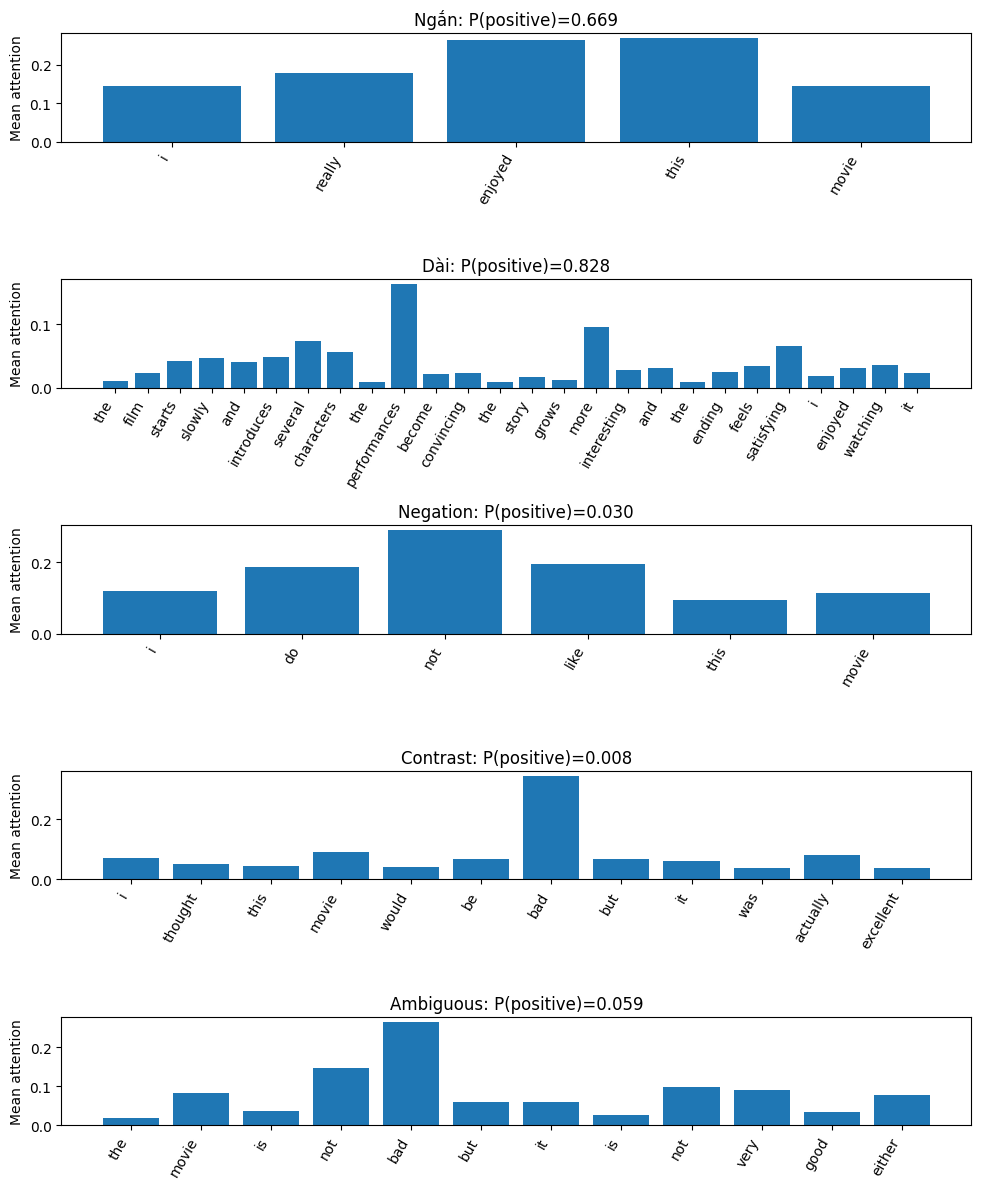

In [28]:
def analyze_transformer_review(review, run):
    normalized = normalize_review(review)
    encoded, lengths = encode_reviews([normalized], vocab, MAX_STORED_LENGTH)
    max_length = run["max_length"]
    token_ids = torch.as_tensor(
        encoded[:, :max_length].astype(np.int64)
    ).to(DEVICE)
    length_tensor = torch.as_tensor(
        np.minimum(lengths, max_length).astype(np.int64)
    )
    tokens = tokenize(normalized)[:max_length]

    model = run["model"]
    model.eval()
    with torch.no_grad():
        logits, attention = model(
            token_ids, length_tensor, return_attention=True
        )
        probability = torch.sigmoid(logits).item()

    mean_attention = attention[0].mean(dim=0)
    if model.pooling == "cls":
        token_importance = mean_attention[0, 1:len(tokens)+1].cpu().numpy()
        token_attention_matrix = mean_attention[1:len(tokens)+1, 1:len(tokens)+1].cpu().numpy()
    else:
        token_attention_matrix = mean_attention[:len(tokens), :len(tokens)].cpu().numpy()
        token_importance = token_attention_matrix.mean(axis=0)

    top_indices = np.argsort(token_importance)[-5:][::-1]
    top_tokens = [
        (tokens[index], float(token_importance[index]))
        for index in top_indices
    ]
    return tokens, probability, top_tokens, token_attention_matrix

application_reviews = [
    ("Ngắn", "I really enjoyed this movie."),
    ("Dài", (
        "The film starts slowly and introduces several characters. "
        "The performances become convincing, the story grows more interesting, "
        "and the ending feels satisfying. I enjoyed watching it."
    )),
    ("Negation", "I do not like this movie."),
    ("Contrast", "I thought this movie would be bad, but it was actually excellent."),
    ("Ambiguous", "The movie is not bad, but it is not very good either."),
]

application_rows = []
application_attention_data = []
for review_type, review in application_reviews:
    tokens, probability, top_tokens, attention_matrix = analyze_transformer_review(
        review, selected_transformer_run
    )
    prediction = "positive" if probability >= 0.5 else "negative"
    application_rows.append({
        "Loại câu": review_type,
        "Review": review,
        "Dự đoán": prediction,
        "P(positive)": probability,
        "Top attention tokens": ", ".join(
            f"{token} ({weight:.3f})" for token, weight in top_tokens
        ),
    })
    application_attention_data.append(
        (review_type, tokens, probability, attention_matrix, top_tokens)
    )
    add_result(
        "Application",
        model=f"Transformer-{selected_transformer_pooling}",
        pooling=selected_transformer_pooling,
        split="new review",
        notes=(
            f"type={review_type}; prediction={prediction}; "
            f"P(positive)={probability:.4f}; top={top_tokens}"
        ),
    )

display(pd.DataFrame(application_rows))

fig, axes = plt.subplots(
    len(application_attention_data), 1,
    figsize=(10, 2.4 * len(application_attention_data)),
)
for axis, (review_type, tokens, probability, matrix, top_tokens) in zip(
    axes, application_attention_data
):
    axis.bar(
        range(len(tokens)),
        matrix.mean(axis=0),
    )
    axis.set_xticks(range(len(tokens)), labels=tokens, rotation=60, ha="right")
    axis.set_ylabel("Mean attention")
    axis.set_title(f"{review_type}: P(positive)={probability:.3f}")
fig.tight_layout()
plt.show()
plt.close(fig)


**Nhận xét — Application**

Model dự đoán đúng review dài và câu negation; review ngắn “I really enjoyed this movie” cũng positive (P=0,669). Câu contrast lại negative (P=0,008), và câu ambiguous negative (P=0,059). Với câu contrast, bad có weight cao nhất (0,344), nhưng attention pattern không chứng minh đây là nguyên nhân duy nhất.

## 16. Error analysis

Chọn ít nhất 3 correct và 3 incorrect từ test cho Transformer pooling tốt nhất. Ghi attention pattern để tham khảo, nhưng tự phân loại lỗi.

In [29]:
attention_error_model = selected_transformer_run["model"]
attention_error_test = (
    test_details["Transformer"]
    if selected_transformer_pooling == "Mean"
    else pooling_test_details["CLS"]
)
error_frame = pd.DataFrame({
    "Text": x_test_texts,
    "True": np.where(attention_error_test["targets"] == 1, "positive", "negative"),
    "Predicted": np.where(
        attention_error_test["predictions"] == 1, "positive", "negative"
    ),
})
error_frame["Correct"] = error_frame["True"] == error_frame["Predicted"]

correct_examples = error_frame[error_frame["Correct"]].sample(
    n=min(3, int(error_frame["Correct"].sum())),
    random_state=RANDOM_STATE,
).copy()
incorrect_examples = error_frame[~error_frame["Correct"]].sample(
    n=min(3, int((~error_frame["Correct"]).sum())),
    random_state=RANDOM_STATE,
).copy()

def top_attention_for_error(text, run, top_n=5):
    _, _, token_weights, _ = analyze_transformer_review(text, run)
    return ", ".join(f"{token} ({weight:.3f})" for token, weight in token_weights)

correct_examples["Top attention tokens"] = correct_examples["Text"].map(
    lambda text: top_attention_for_error(text, selected_transformer_run)
)
incorrect_examples["Top attention tokens"] = incorrect_examples["Text"].map(
    lambda text: top_attention_for_error(text, selected_transformer_run)
)
print("Ví dụ phân loại đúng")
display(correct_examples[["Text", "True", "Predicted", "Top attention tokens"]])
print("Ví dụ phân loại sai")
display(incorrect_examples[["Text", "True", "Predicted", "Top attention tokens"]])


Ví dụ phân loại đúng


,Text,True,Predicted,Top attention tokens
2328,"ettore scola, one of the most refined and gran...",positive,positive,"dvd (0.056), big (0.049), grand (0.048), scola..."
9105,"very literate, intelligent drama about a group...",positive,positive,"trying (0.048), literate (0.047), robards (0.0..."
8241,the shanghai cobra starts out like gangbusters...,negative,negative,"moreland (0.067), unfortunately (0.065), stand..."


Ví dụ phân loại sai


,Text,True,Predicted,Top attention tokens
5137,"after ""attack of the fifty foot woman"" with al...",positive,negative,"cute (0.056), torch (0.055), world (0.043), ob..."
9510,based on one of the books by gabriel marquez a...,negative,positive,"wherein (0.070), books (0.068), brilliant (0.0..."
9729,in the late sixties director sergio corbucci m...,positive,negative,"poor (0.081), three (0.062), best (0.051), dir..."


**Nhận xét — Error analysis**

Confusion matrix có 1.586 false negatives và 924 false positives. Hai review positive bị nhầm negative đều dài hơn 64 tokens, và phần khen chính xuất hiện sau đoạn đầu; truncation là một giả thuyết hợp lý. Review negative bị nhầm positive có token brilliant/books được attention cao nhưng overall vẫn chê phim. Đây chỉ là giả thuyết đối chiếu với review, không phải kết luận từ heatmap.

**Nhận xét — Error analysis**

Test confusion matrix có 1.586 false negatives và 924 false positives. Hai review positive bị nhầm negative dài hơn max_length=64; phần khen nằm sau đoạn đầu nhiều từ phê bình, nên truncation là một giả thuyết hợp lý. Một review negative bị nhầm positive có từ “brilliant” trong ngữ cảnh khen sách nhưng chê phim. Attention pattern chỉ hỗ trợ quan sát, không chứng minh nguyên nhân. Chi tiết 3 mẫu đúng/sai nằm trong error_analysis.md.

## 17. Prediction verification

Giữ nguyên prediction ban đầu trong prediction.md; đối chiếu từng dự đoán với kết quả experiment.

In [30]:
head4_val = head_runs[4]["validation_metrics"]["f1_macro"]
best_head_count = max(
    head_runs,
    key=lambda head: head_runs[head]["validation_metrics"]["f1_macro"],
)
head4_mean = head_runs[4]["model"]

with torch.no_grad():
    permutation_no_pe_difference = permutation_results["difference_without_pe"]
    permutation_pe_difference = permutation_results["difference_with_pe"]

head_values = head_table.set_index("Heads")["Val F1 macro"].to_dict()
parallel_time_comparison = {
    "LSTM": lstm_run["training_seconds"],
    "Transformer": head_runs[4]["training_seconds"],
}
length32 = sequence_table.loc[
    sequence_table["max_length"] == 32, "test_f1_macro"
].iloc[0]
length256 = sequence_table.loc[
    sequence_table["max_length"] == 256, "test_f1_macro"
].iloc[0]

prediction_verification = pd.DataFrame([
    {
        "#": 1,
        "Prediction ban đầu": "Transformer xử lý token song song hơn RNN",
        "Kết quả": (
            f"Kiến trúc song song; train times LSTM "
            f"{parallel_time_comparison['LSTM']:.1f}s, Transformer "
            f"{parallel_time_comparison['Transformer']:.1f}s trên CPU."
        ),
        "Giải thích": "Song song hóa là đặc tính tính toán; thời gian thực tế còn tùy T, batch và implementation.",
    },
    {
        "#": 2,
        "Prediction ban đầu": "Không PE thì model không có thông tin thứ tự",
        "Kết quả": f"Mean-representation distance không PE={permutation_no_pe_difference:.6g}; có PE={permutation_pe_difference:.6g}.",
        "Giải thích": "Kết quả toy experiment phù hợp với permutation test.",
    },
    {
        "#": 3,
        "Prediction ban đầu": "Cùng token, khác thứ tự khó phân biệt nếu thiếu PE",
        "Kết quả": f"Khoảng cách pooled biểu diễn thay đổi từ {permutation_no_pe_difference:.6g} lên {permutation_pe_difference:.6g} khi thêm PE.",
        "Giải thích": "PE đưa thông tin vị trí vào trước encoder.",
    },
    {
        "#": 4,
        "Prediction ban đầu": "Các heads có thể học pattern khác nhau",
        "Kết quả": f"Pairwise cosine giữa attention maps được in ở bảng Experiment 3; best head count theo validation là {best_head_count}.",
        "Giải thích": "Pattern có thể khác hoặc trùng; không tự gán nhãn ngôn ngữ cho head.",
    },
    {
        "#": 5,
        "Prediction ban đầu": "Nhiều heads không chắc làm accuracy tăng",
        "Kết quả": f"F1 macro theo heads: {head_values}.",
        "Giải thích": "Đối chiếu trực tiếp các F1; d_model được giữ cố định ở 128.",
    },
    {
        "#": 6,
        "Prediction ban đầu": "Transformer không phải lúc nào cũng nhanh hơn RNN",
        "Kết quả": f"Train time đã đo ở base length; T=32 F1={length32:.4f}, T=256 F1={length256:.4f}.",
        "Giải thích": "Attention cho tương tác trực tiếp nhưng cost/memory tăng theo T².",
    },
])
display(prediction_verification)


,#,Prediction ban đầu,Kết quả,Giải thích
0,1,Transformer xử lý token song song hơn RNN,"Kiến trúc song song; train times LSTM 236.6s, ...",Song song hóa là đặc tính tính toán; thời gian...
1,2,Không PE thì model không có thông tin thứ tự,Mean-representation distance không PE=0; có PE...,Kết quả toy experiment phù hợp với permutation...
2,3,"Cùng token, khác thứ tự khó phân biệt nếu thiế...",Khoảng cách pooled biểu diễn thay đổi từ 0 lên...,PE đưa thông tin vị trí vào trước encoder.
3,4,Các heads có thể học pattern khác nhau,Pairwise cosine giữa attention maps được in ở ...,Pattern có thể khác hoặc trùng; không tự gán n...
4,5,Nhiều heads không chắc làm accuracy tăng,"F1 macro theo heads: {1: 0.7464500889209641, 2...",Đối chiếu trực tiếp các F1; d_model được giữ c...
5,6,Transformer không phải lúc nào cũng nhanh hơn RNN,Train time đã đo ở base length; T=32 F1=0.7003...,Attention cho tương tác trực tiếp nhưng cost/m...


## 18. Lưu kết quả

In [31]:
results_df = pd.DataFrame(results_rows, columns=RESULT_COLUMNS).drop_duplicates()
results_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8-sig")
display(results_df)
print(f"Đã lưu results.csv tại: {RESULTS_PATH}")
print("Ảnh được lưu:", POSITIONAL_ENCODING_PATH.name,
      ATTENTION_HEADS_PATH.name, LEARNING_CURVES_PATH.name,
      CONFUSION_MATRIX_PATH.name)


,experiment,model,pooling,split,accuracy,precision_positive,recall_positive,f1_positive,f1_macro,loss,training_time_seconds,epochs_trained,parameters,d_model,n_heads,d_k,sequence_length,tokens_retained_percent,attention_matrix_elements,notes
0,Experiment 2 - Head count,Transformer-1 heads,mean,validation,0.746975,0.774955,0.698815,0.734918,0.746450,0.514432,110.037725,3.0,3972609.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
1,Experiment 2 - Head count,Transformer-2 heads,mean,validation,0.748487,0.782737,0.690577,0.733775,0.747717,0.508276,120.015135,3.0,3972609.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
2,Experiment 2 - Head count,Transformer-4 heads,mean,validation,0.749697,0.792909,0.678521,0.731269,0.748515,0.504704,134.217229,3.0,3972609.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
3,Experiment 2 - Head count,Transformer-8 heads,mean,validation,0.748689,0.793112,0.675507,0.729601,0.747430,0.505873,166.750152,3.0,3972609.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
4,Experiment 4 - LSTM vs Transformer,LSTM,LSTM,validation,0.740722,0.770094,0.689170,0.727388,0.740100,0.515416,236.649756,3.0,3972225.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
5,Experiment 4 - LSTM vs Transformer,Transformer-4 heads,mean,validation,0.749697,0.792909,0.678521,0.731269,0.748515,0.504704,134.217229,3.0,3972609.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
6,Experiment 4 - LSTM vs Transformer,LSTM,LSTM,test,0.744151,0.769197,0.700422,0.733200,0.743719,0.516842,236.649756,3.0,3972225.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
7,Experiment 4 - LSTM vs Transformer,Transformer-4 heads,mean,test,0.746874,0.785863,0.681334,0.729875,0.745867,0.503486,134.217229,3.0,3972609.0,128.0,NaN,NaN,64.0,NaN,4096.0,"Checkpoint theo validation loss, epoch 3."
8,Experiment 5 - Sequence length,Transformer-4 heads,mean,test,0.706535,0.662219,0.847699,0.743567,0.700284,0.552686,60.030896,2.0,3972609.0,128.0,4.0,32.0,32.0,13.831357,1024.0,"Sequence sweep batch=64, epochs=2."
9,Experiment 5 - Sequence length,Transformer-4 heads,mean,test,0.767547,0.758114,0.788427,0.772974,0.767415,0.476194,101.770194,2.0,3972609.0,128.0,4.0,32.0,64.0,27.360832,4096.0,"Sequence sweep batch=64, epochs=2."


Đã lưu results.csv tại: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab07\results.csv
Ảnh được lưu: positional_encoding.png attention_heads.png learning_curves.png confusion_matrix.png
